<a href="https://colab.research.google.com/github/amelkhelifi-del/Projet/blob/main/TP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [ ]:
# Write your code here
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"Matplotlib version: {plt.matplotlib.__version__}")
print(f"Seaborn version: {sns.__version__}")
np.random.seed(1)

NumPy version: 2.4.6
Pandas version: 2.2.3
Matplotlib version: 3.10.0
Seaborn version: 0.13.2


In [ ]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [ ]:
# Write your code here
import numpy as np

S = np.array([

    [10, 4],
    [2, 1],
    [7, 3],
    [1, 2]
])

theta = np.array([0.3, 0.7])
bias = 0.5

# 1. Compute linear combination z
z = S @ theta + bias
print("z =", z)

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5)
probabilities = 1 / (1 + np.exp(-z))
print("Probabilities =", probabilities)

# Identify predicted spam emails
predicated_spam = probabilities >= 0.5
print("predicated_pam =",predicated_spam)


z = [6.3 1.8 4.7 2.2]
Probabilities = [0.99816706 0.85814894 0.9909867  0.90024951]
predicated_pam = [ True  True  True  True]


In [ ]:
# Auto-graded cell (S)
# Skip it

In [ ]:
# Auto-graded cell (theta)
# Skip it

In [ ]:
# Auto-graded cell (bias)
# Skip it

In [ ]:
# Auto-graded cell (z)
# Skip it

In [ ]:
# Auto-graded cell (probabilities)
# Skip it

In [ ]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [1]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
import numpy as np
import pandas as pd

# Create the log of 300 login events
rng = np.random.default_rng(1)
n = 300

log = pd.DataFrame({
    "user": rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
    "hour": rng.integers(0, 24, n),
    "failed_attempts": rng.poisson(0.4, n),
    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
    "duration_min": rng.gamma(2, 8, n).round(1)
})

print(log.head())
print("Number of login events:", len(log))

     user  hour  failed_attempts country  duration_min
0  yacine     2                0      DZ          24.0
1  yacine    23                0      FR          23.2
2    nour    11                0      FR           4.8
3   karim     9                0      DZ           4.2
4     ali    17                0      DZ          21.8
Number of login events: 300


In [ ]:
# Auto graded cell (log)
# skip it

In [3]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"

# Write your code here
idx = rng.choice(log.index, 12, replace=False)

log.loc[idx, "failed_attempts"] = rng.integers(5, 11, 12)

print(log.loc[idx, "failed_attempts"])

55      6
117     5
247     7
202    10
145     5
131    10
295     7
162     8
154     7
156     6
204     8
211     9
Name: failed_attempts, dtype: int64


In [ ]:
# Autograded cell (Failed attempts)
# Skip it

In [2]:
# Insert 10 missing values randomly

# Write your code here
missing_idx = rng.choice(log.index, 10, replace=False)

log.loc[missing_idx, "country"] = np.nan

print(log.loc[missing_idx])

       user  hour  failed_attempts country  duration_min
47    karim     9                0     NaN          18.5
124   karim     8                1     NaN           3.7
86    karim    22                0     NaN          35.8
251    sara     1                0     NaN          50.6
284  yacine    11                0     NaN          10.9
123     ali    23                0     NaN          11.6
271    nour    19                0     NaN          33.4
7     karim    20                1     NaN           2.5
220     ali     1                0     NaN          10.8
228     ali    13                0     NaN          50.5


In [ ]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [5]:
# Write your code here

ru_log_at_least_five_attempts = log[
    (log["country"] == "RU") &
    (log["failed_attempts"] >= 5)
]

print("Number of suspicious RU logins:",
      len(ru_log_at_least_five_attempts))

Number of suspicious RU logins: 3


In [ ]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [6]:
# Write your code here


user_max_failed_attempts = (
    log.groupby("user")["failed_attempts"]
    .sum()
    .sort_values(ascending=False)
)

print(user_max_failed_attempts)

user
sara      65
karim     52
ali       36
yacine    27
nour      25
Name: failed_attempts, dtype: int64


In [ ]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [7]:
# Write your code here
log["long_session"] = (log["duration_min"] > 30).astype(int)

print(log[["duration_min", "long_session"]].head(10))

   duration_min  long_session
0          24.0             0
1          23.2             0
2           4.8             0
3           4.2             0
4          21.8             0
5          22.1             0
6           1.7             0
7           2.5             0
8          10.2             0
9           5.2             0


In [ ]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

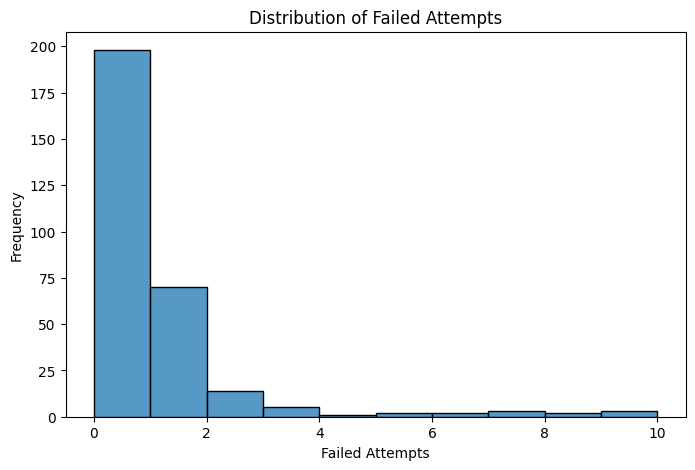

In [9]:
# Draw the histogram of failed_attempts.
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(data=log, x="failed_attempts", bins=10)

plt.title("Distribution of Failed Attempts")
plt.xlabel("Failed Attempts")
plt.ylabel("Frequency")

plt.show()

In [ ]:
# Auto-graded cell - Skip it...

In [ ]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

IndentationError: unexpected indent (1357432129.py, line 2)

In [ ]:
# Write your code here
# answer_q2 = "B"

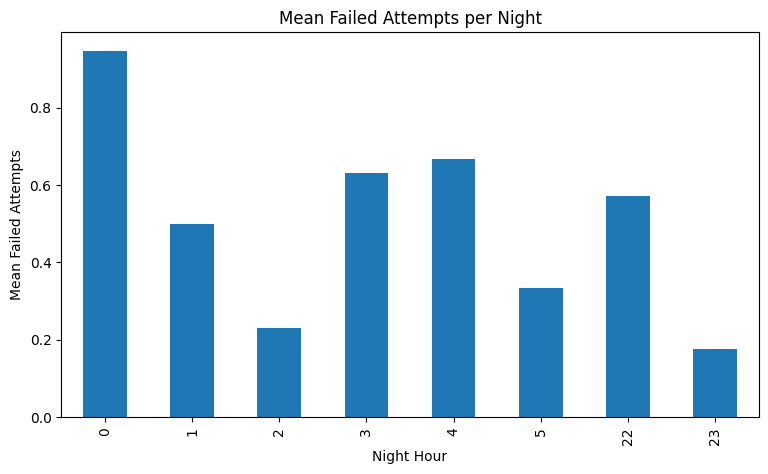

In [10]:
# 3. Draw a bar chart of the mean failed_attempts per night value.

# Write your code here
night_log = log[
    (log["hour"] >= 22) | (log["hour"] < 6)
]

# Calculate mean failed attempts per night hour
night_mean = night_log.groupby("hour")["failed_attempts"].mean()

# Draw bar chart
plt.figure(figsize=(9, 5))
night_mean.plot(kind="bar")

plt.title("Mean Failed Attempts per Night")
plt.xlabel("Night Hour")
plt.ylabel("Mean Failed Attempts")

plt.show()

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [ ]:
# Write your code here
# Please write a sentence response instead of code
"X[:, 2] returns all 300 elements from the third column of the NumPy array X"

Q2. Give the Pandas command that shows the number of missing values


```
# Ce texte est au format code\
```


*   Élément de liste

*   Élément de liste

---


*   Élément de liste


*   Élément de liste

in each column of a given df. (01 point)

In [11]:
log.isnull().sum()

,0
user,0
hour,0
failed_attempts,0
country,10
duration_min,0
long_session,0


Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

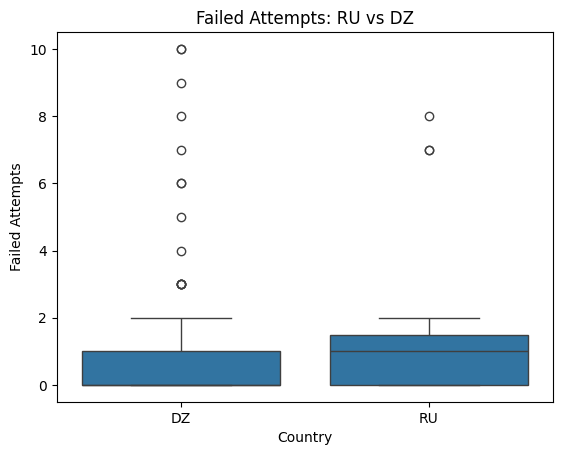

In [13]:
# Write your code here
sns.boxplot(
    data=log[log["country"].isin(["RU", "DZ"])],
    x="country",
    y="failed_attempts"
)

plt.title("Failed Attempts: RU vs DZ")
plt.xlabel("Country")
plt.ylabel("Failed Attempts")
plt.show()

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [14]:
# Write your code here
"We scale features to put them on a similar range so that features with larger values do not dominate the model during training"

'We scale features to put them on a similar range so that features with larger values do not dominate the model during training'

Commit the logins_clean.csv.(0.5 point)

In [ ]:
# save the cleaned table in login_clean.csv
# Write your code here

import pandas as pd

df = pd.read_csv("logins.csv")


FileNotFoundError: [Errno 2] No such file or directory: 'logins.csv'

In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [ ]:
# Write your code here
import pandas as pd
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("logins_clean.csv")

cols = ["hour", "failed_attempts", "duration_min", "night"]

X = df[cols].to_numpy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Shape of X:", X.shape)
print("Shape of X_scaled:", X_scaled.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'logins_clean.csv'

In [ ]:
import numpy as np
import pandas as pd
